### Wave on a String.

Solved the 1D wave equation using the finite difference method. Code 1: with fixed endpoints. Code 2: without fixed endpoints.

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, clear_output
import time

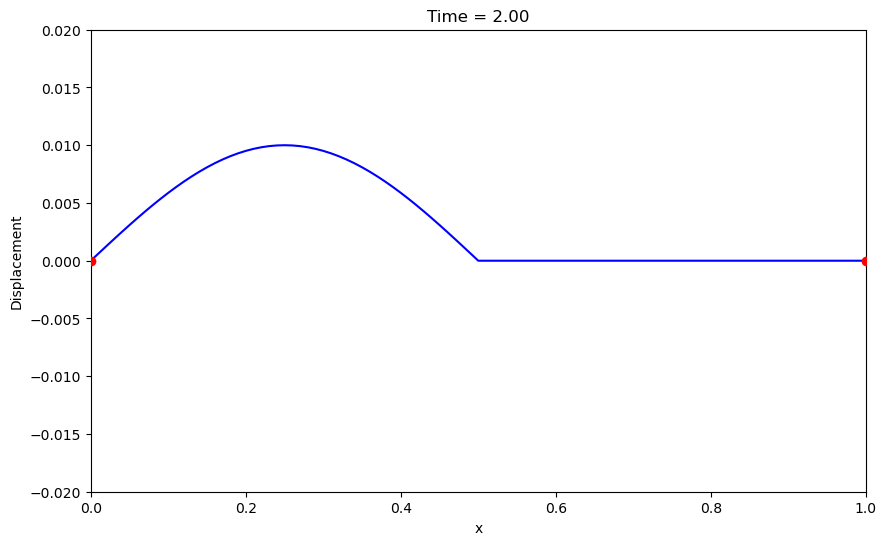

In [6]:
#Define the parameters.

L  = 1
mu = 1
t = 0
T =1

dx = 0.01
dt = 0.01 #we can't just pick any values for dx and dt. If the speed of 
#your wave is such that it moves the distance dx in less time than dt, it blows up.

R = dt ** 2 * T/(dx ** 2 * mu)

# Generate the points on the string and include both the fixed endpoints.

x = np.linspace(0, L, int(round(L/dx)) + 1)

# Initialize three lists with zeros
fnew = np.zeros(len(x))  # k+1 (next time step)
fnow = np.zeros(len(x))  # k   (current time step)
fold = np.zeros(len(x)) # k-1 (previous time step)

# Initial displacement: half-sine pulse
for i in range(len(x)):
    if x[i] < L/2:
        fnow[i] = 0.01 * np.sin(2 * np.pi * x[i] / L)

# Approximate initial condition for previous time step
fold = fnow.copy()

# Fix both endpoints
fnow[0] = 0
fnow[-1] = 0

fold[0] = 0
fold[-1] = 0

# Time evolution loop

while t < 2:

    # Calculate displacement at interior points
    
    for i in range(1, len(x)-1):
        fnew[i] = (R * (fnow[i+1] + fnow[i-1] - 2*fnow[i]) - fold[i] + 2*fnow[i])

    # Keep BOTH endpoints fixed
    
    fnew[0] = 0
    fnew[-1] = 0

    # Update previous and current displacement
    
    fold = fnow.copy()
    fnow = fnew.copy()


    
    t = t + dt
    

    # Update graph
    
    clear_output(wait=True)

    plt.figure(figsize=(10, 6))
    plt.plot(x, fnow, color='blue')

    # Mark the two fixed endpoints
    
    plt.scatter([0, L], [0, 0], color='red', zorder=5)

    plt.xlabel('x')
    plt.ylabel('Displacement')
    plt.title(f'Time = {t:.2f}')
    plt.xlim(0, L)
    plt.ylim(-0.02, 0.02)

    display(plt.gcf())
    plt.close()

    time.sleep(0.01)

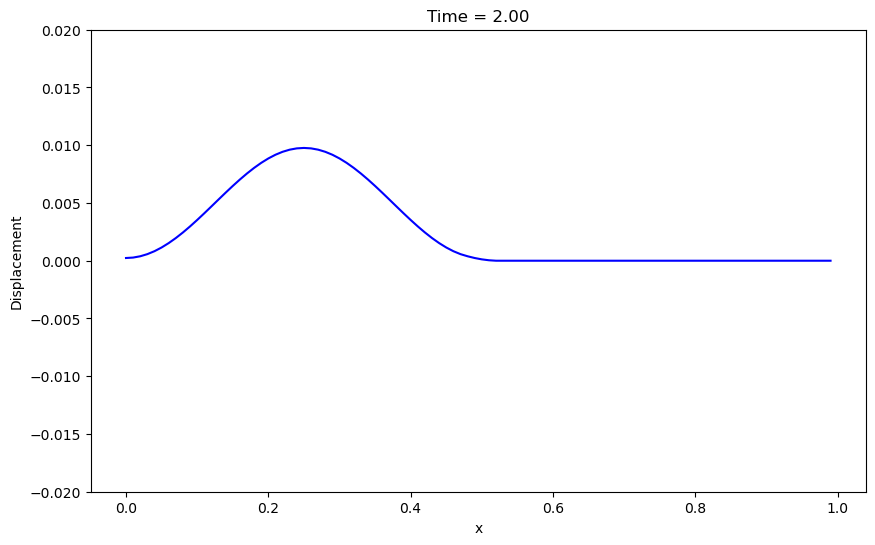

In [7]:
L  = 1
mu = 1
t = 0
T =1
dx = 0.01
dt = 0.01 #we can't just pick any values for dx and dt. If the speed of 
#your wave is such that it moves the distance dx in less time than dt, it blows up.
R = dt**2*T/(dx**2*mu)


# Generate spatial points
xt = 0
x = []

while xt < L:
    x = x + [xt]
    xt = xt + dx

#print(x)

# Initialize three lists with zeros
fnew = []  # k+1 (next time step)
fnow = []  # k   (current time step)
fold = []  # k-1 (previous time step)

for i in range(len(x)):
    fnew = np.zeros(len(x))  
    fnow = np.zeros(len(x))  
    fold = np.zeros(len(x)) 

#two copies of the initial string shape, so the simulation has both the current and previous values it needs to begin calculating motion.

for i in range(len(x)):
    if x[i] < L/2:
        fnow[i] = 0.01 * (np.sin(2 * np.pi * x[i] / L))**2  # to satisfy the same zero-displacement and zero-slope conditions
        
fold = fnow.copy()

plt.figure(figsize=(5, 2))
plt.plot(x, fnow)
plt.xlabel('x')
plt.ylabel('f')
plt.show()

while t < 2:
    fdata = []

    for i in range(1, len(x)-1):              #runs from 1 to 99 excludes 0 and 100
        
        fnew[i] = R * (fnow[i+1] + fnow[i-1] - 2*fnow[i]) - fold[i] + 2*fnow[i]

       # Free left endpoint  # CHANGES

    fnew[0] = (
        2*fnow[0] - fold[0]
        + 2*R*(fnow[1] - fnow[0])
    )  # CHANGES

    # Free right endpoint  # CHANGES

    fnew[-1] = (
        2*fnow[-1] - fold[-1]
        + 2*R*(fnow[-2] - fnow[-1])
    )  # CHANGES
      
    fold = fnow.copy()
    fnow = fnew.copy() 
    

 
         #  Advance to the next shape.

    for i in range(len(x)):
        
        fdata = fdata + [[x[i], fnew[i]]]


    t = t + dt
    
    # Update graph
    clear_output(wait=True)
    plt.figure(figsize=(10,6))
    plt.plot(x, fnew, color='blue')
    
    plt.xlabel('x')
    plt.ylabel('Displacement')
    plt.title(f'Time = {t:.2f}')
    
    plt.ylim(-0.02, 0.02)
    
    display(plt.gcf())
    plt.close()

    time.sleep(0.01)







        